In [35]:
import os
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [36]:
data = pd.read_csv('Titanic-Dataset.csv')

data = data[['Survived', 'Pclass', 'Age', 'Fare']]
data = data.dropna(subset=['Age'])

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import itertools
import pickle

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    Функция для построения матрицы ошибок.
    cm - матрица ошибок
    classes - список классов
    normalize - если True, то значения матрицы ошибок нормализуются к 1
    title - заголовок графика
    cmap - цветовая схема для отображения графика
    """

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

accuracy 0.7132867132867133
Confusion matrix, without normalization
              precision    recall  f1-score   support

Not Survived       0.69      0.89      0.78        81
    Survived       0.77      0.48      0.59        62

    accuracy                           0.71       143
   macro avg       0.73      0.69      0.69       143
weighted avg       0.73      0.71      0.70       143



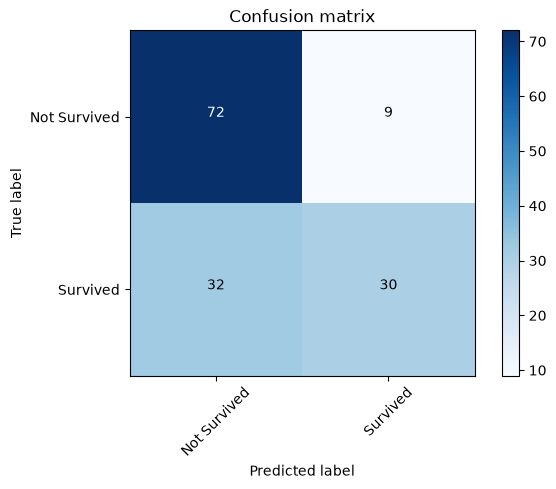

In [ ]:
def experiment(max_depth, min_samples_split):
    # Создание и обучение модели решающего дерева
    model = DecisionTreeClassifier(max_depth=max_depth, min_samples_split=min_samples_split)
    model.fit(train.drop('Survived', axis=1), train['Survived'])

    # Вычисление метрик 
    preds = model.predict(test.drop('Survived', axis=1))
    acc = accuracy_score(test['Survived'], preds)
    cm = confusion_matrix(test['Survived'], preds)

    print("accuracy", acc)

    # Визуализация матрицы ошибок
    plot_confusion_matrix(cm, classes=['Not Survived', 'Survived'])

    # Вывод classification report
    report = classification_report(test['Survived'], preds, target_names=['Not Survived', 'Survived'])
    print(report)

    # Сохранение модели в формате pickle
    with open('model.pkl', 'wb') as f:
        pickle.dump(model, f)


# Определение гиперпараметров модели
max_depth = 5
min_samples_split = 150

experiment(max_depth, min_samples_split)

In [45]:
with open('model.pkl', 'rb') as f:
    model = pickle.load(f)

new_data = pd.DataFrame({
    'Pclass': [3],
    'Age': [2],
    'Fare': [10]
})

predictions = model.predict(new_data)

print(predictions)


[1]


In [1]:
import requests

def prediction_model(data):
    url = 'http://localhost:500/predict'

    response = requests.post(url, json=data)

    if response.status_code == 200:
        return response.json()
    else:
        return {"error" : f"Request failed with status code {response.status_code}"}

data = {
    'Pclass' : 1,
    'Age' : 22,
    'Fare' : 150
}

prediction = prediction_model(data)
print(prediction)

{'prediction': 'Survived'}
